# BT4012 Fraud Analytics Group 14: FiGraph

## Loading Libraries

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import torch
from torch_geometric.data import Data
from sklearn.preprocessing import RobustScaler

c:\Users\Timothy\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Data Loading and exploration

In [2]:
df = pd.read_parquet("../data/processed/tabular_clean")


def read_edges(year):
    path = f"../data/{year}/edges{year}.csv"
    e = pd.read_csv(path, dtype=str)
    if e.columns[0][1:].isdigit():
        e = pd.read_csv(path, dtype=str, header=None)
    e = e.iloc[:, :3]
    e.columns = ["src", "dst", "etype"]
    e["Year"] = year
    return e


edges = pd.concat([read_edges(y) for y in range(2014, 2023)], ignore_index=True)
print(f"tabular: {len(df):,} company-year rows, {df['nodeID'].nunique():,} companies")
print(f"edges:   {len(edges):,}")
edges.head()


tabular: 33,664 company-year rows, 5,254 companies
edges:   1,040,997


,src,dst,etype,Year
0,U175010,L000801,Related-party transaction,2014
1,U180818,L002057,Related-party transaction,2014
2,H34660,L002588,Investment,2014
3,U274201,L600823,Related-party transaction,2014
4,H76120,L603555,Investment,2014


### Data Exploration: Edge type counts

In [3]:
nodes = pd.concat([edges[["src", "Year"]].set_axis(["node", "Year"], axis=1),
                   edges[["dst", "Year"]].set_axis(["node", "Year"], axis=1)],
                  ignore_index=True).drop_duplicates()
nodes["ntype"] = nodes["node"].str[0]  # ID prefix = node type, L = listed company

print(f"unique nodes: {nodes['node'].nunique():,}")
print("\nunique nodes by type:")
print(nodes.drop_duplicates("node")["ntype"].value_counts())
print("\nnodes per year by type:")
print(pd.crosstab(nodes["Year"], nodes["ntype"], margins=True))
print("\nedges per year by relation type:")
print(pd.crosstab(edges["Year"], edges["etype"], margins=True))

unique nodes: 236,692

unique nodes by type:
ntype
U    162038
H     67906
L      5254
O      1444
A        50
Name: count, dtype: int64

nodes per year by type:
ntype    A       H      L     O       U     All
Year                                           
2014    40   17942   2631   315   32750   53678
2015    40   17721   2824   346   37243   58174
2016    40   17904   3125   359   43617   65045
2017    40   20391   3503   385   51499   75818
2018    40   21714   3596   354   55135   80839
2019    40   23413   3815   390   58875   86533
2020    41   26431   4269   522   66123   97386
2021    45   28913   4769   565   73173  107465
2022    44   28789   5132   538   70967  105470
All    370  203218  33664  3774  489382  730408

edges per year by relation type:
etype  Audit  Investment  Related-party transaction  Supply chain      All
Year                                                                      
2014    2631       43587                      33509           231    79958
201

### Data Exploration: Class Imbalance Year on Year

      companies  fraud  fraud_rate
Year                              
2014       2631     95      0.0361
2015       2824    134      0.0475
2016       3125    173      0.0554
2017       3503    205      0.0585
2018       3596    225      0.0626
2019       3815    214      0.0561
2020       4269    207      0.0485
2021       4769    183      0.0384
2022       5132    123      0.0240

overall fraud rate: 4.63%


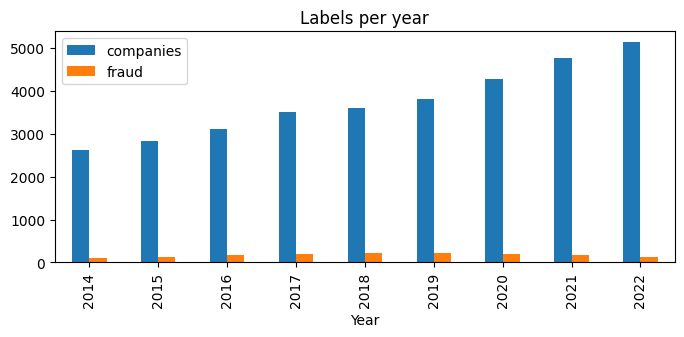

In [4]:
labels = df.groupby("Year")["Label"].agg(companies="size", fraud="sum", fraud_rate="mean")
print(labels.round(4))
print(f"\noverall fraud rate: {df['Label'].mean():.2%}")

ax = labels[["companies", "fraud"]].plot.bar(figsize=(8, 3), title="Labels per year")
plt.show()

## Edge Pruning

Keep only background nodes (`U`, `H`, `O`, `A`) when they connect companies

- every company - company edge (L - L)
- company - background edges where the background node links 2+ companies (L - X - L,
  e.g. a shared auditor or investor)

Before pruning, each company-year's edge counts per relation are saved as `deg_features`, so the dropped edges can still reach the model as tabular features.

In [5]:
# Step 1: keep only edges with at least one listed company
src_is_L = edges["src"].str.startswith("L")
dst_is_L = edges["dst"].str.startswith("L")
e = edges[src_is_L | dst_is_L].copy()
e["company"] = np.where(e["src"].str.startswith("L"), e["src"], e["dst"])
e["other"] = np.where(e["src"].str.startswith("L"), e["dst"], e["src"])
print(f"step 1, edges touching a company: {len(edges):,} -> {len(e):,}")

# Step 2: edge counts per company-year and relation, saved BEFORE pruning
deg_features = (e.groupby(["company", "Year", "etype"]).size()
                 .unstack(fill_value=0).add_prefix("n_").reset_index()
                 .rename(columns={"company": "nodeID"}))
deg_features.columns.name = None
deg_features.head()

step 1, edges touching a company: 1,040,997 -> 1,040,997


,nodeID,Year,n_Audit,n_Investment,n_Related-party transaction,n_Supply chain
0,L000001,2014,1,69,5,0
1,L000001,2015,1,113,3,0
2,L000001,2016,1,65,3,0
3,L000001,2017,1,59,1,0
4,L000001,2018,1,42,1,0


In [6]:
# Step 3: company-company edges are all kept; background nodes only if shared by 2+ companies
ll = e[e["other"].str.startswith("L")]
bg = e[~e["other"].str.startswith("L")]
n_companies = bg.groupby(["other", "Year"])["company"].transform("nunique")
bg = bg[n_companies >= 2]
print(f"step 3, company-company edges: {len(ll):,}  shared background edges: {len(bg):,}")

step 3, company-company edges: 83,770  shared background edges: 359,709


In [7]:
sub_edges = (pd.concat([ll, bg])[["src", "dst", "etype", "Year"]]
               .sort_values(["Year", "src", "dst", "etype"], ignore_index=True))

sub_nodes = pd.unique(pd.concat([sub_edges["src"], sub_edges["dst"]]))
print(f"edges: {len(edges):,} -> {len(sub_edges):,} ({len(sub_edges) / len(edges):.1%})")
print(f"nodes: {nodes['node'].nunique():,} -> {len(sub_nodes):,}")

print("\nedges by relation type:")
print(pd.DataFrame({"full": edges["etype"].value_counts(),
                    "kept": sub_edges["etype"].value_counts()}).fillna(0).astype(int)
        .assign(kept_share=lambda d: (d["kept"] / d["full"]).round(3)))

print("\nkept nodes by type:")
print(pd.Series(sub_nodes).str[0].value_counts())

edges: 1,040,997 -> 443,479 (42.6%)
nodes: 236,692 -> 46,846

edges by relation type:
                             full    kept  kept_share
etype                                                
Audit                       33551   33551       1.000
Investment                 474345  254188       0.536
Related-party transaction  530743  153382       0.289
Supply chain                 2358    2358       1.000

kept nodes by type:
U    27219
H    13905
L     5254
O      418
A       50
Name: count, dtype: int64


# Walkforward train/test folds

Expanding window: train on every year before the test year, test on that year.

| split | train on | test on |
|---|---|---|
| 0 | 2014-2018 | 2019 |
| 1 | 2014-2019 | 2020 |
| 2 | 2014-2020 | 2021 |
| 3 | 2014-2021 | 2022 |

The same company can be in train (earlier years) and test (later year). That is realistic, as long as
every feature for year *y* uses only data from year *y* and before, and graph inputs for year *y* use
only that year's edges. Fraud labels for recent years are probably incomplete (fraud is often found
later), so expect lower scores on 2021-2022.

In [8]:
splits = []
for i, test_year in enumerate(range(2019, 2023)):
    rows = df[["nodeID", "Year", "Label"]].copy()
    rows["split"] = i
    rows["role"] = np.where(rows["Year"] < test_year, "train",
                            np.where(rows["Year"] == test_year, "test", "unused"))
    splits.append(rows[rows["role"] != "unused"])
splits = pd.concat(splits, ignore_index=True)

summary = splits.groupby(["split", "role"]).agg(
    years=("Year", lambda y: f"{y.min()}-{y.max()}"), rows=("Label", "size"),
    fraud=("Label", "sum"), fraud_rate=("Label", "mean")).round(4)
print(summary)

# Checks: no test year leaks into its own training set
for i, s in splits.groupby("split"):
    assert s.loc[s["role"] == "train", "Year"].max() < s.loc[s["role"] == "test", "Year"].min()

                 years   rows  fraud  fraud_rate
split role                                      
0     test   2019-2019   3815    214      0.0561
      train  2014-2018  15679    832      0.0531
1     test   2020-2020   4269    207      0.0485
      train  2014-2019  19494   1046      0.0537
2     test   2021-2021   4769    183      0.0384
      train  2014-2020  23763   1253      0.0527
3     test   2022-2022   5132    123      0.0240
      train  2014-2021  28532   1436      0.0503


In [9]:
out = Path("../data/splits")
out.mkdir(parents=True, exist_ok=True)

splits.to_csv(out / "temporal_splits.csv", index=False)
print(f"saved {len(splits):,} rows to", (out / "temporal_splits.csv").resolve())

saved 105,453 rows to C:\Users\Timothy\Desktop\BT4012 Project\BT4012-Group14\data\splits\temporal_splits.csv


# Edge Creation
Condensing node-node relation into edges
1. Identifying all node chain types
2. Converting each chain into a company - company edge

## Identifying node chain types

In [10]:
ntype = lambda s: s.str[0]
schema = (edges.assign(a=ntype(edges["src"]), b=ntype(edges["dst"]))
               .assign(ends=lambda d: np.where(d["a"] <= d["b"], d["a"] + "-" + d["b"],
                                               d["b"] + "-" + d["a"]))
               .groupby(["etype", "ends"]).size().rename("edges").reset_index())
print(schema.to_string(index=False))

                    etype ends  edges
                    Audit  A-L  33551
               Investment  H-L 218152
               Investment  L-L  70967
               Investment  L-O  16210
               Investment  L-U 169016
Related-party transaction  H-L  69214
Related-party transaction  L-L  10445
Related-party transaction  L-O    885
Related-party transaction  L-U 450199
             Supply chain  L-L   2358


In [11]:
# Counts company pairs per chain type without building the pairs,
# so a big hub (an auditor with 200 clients = 19,900 pairs) can't blow up memory.
lx = e[~e["other"].str.startswith("L")].copy()  # company - background
xy = edges[~edges["src"].str.startswith("L")
           & ~edges["dst"].str.startswith("L")]  # background - background (none in FiGraph)
lx["xtype"] = lx["other"].str[0]
c = (lx.groupby(["other", "xtype", "Year", "etype"])["company"].nunique()
       .unstack("etype", fill_value=0))
rels = list(c.columns)


def label(*parts):
    # relation, node type, relation, ... -> "L -r1- X -r2- L"
    s = "L"
    for i, p in enumerate(parts):
        s += f" -{p}- " if i % 2 == 0 else p
    return s + "L"


# 1 hop: L - r - L
direct = (ll.groupby("etype").size().rename("company_pairs").reset_index()
            .assign(hops=1, chain=lambda d: "L -" + d["etype"] + "- L",
                    biggest_hub_pairs=np.nan)[["hops", "chain", "company_pairs",
                                               "biggest_hub_pairs"]])

# 2 hops: L - r1 - X - r2 - L
rows = []
for i, r1 in enumerate(rels):
    for r2 in rels[i:]:
        n1, n2 = c[r1], c[r2]
        pairs = n1 * (n1 - 1) / 2 if r1 == r2 else n1 * n2
        for xt, row in pairs.groupby(level="xtype").agg(["sum", "max"]).iterrows():
            if row["sum"] > 0:
                rows.append({"hops": 2, "chain": label(r1, xt, r2),
                             "company_pairs": row["sum"], "biggest_hub_pairs": row["max"]})
two_hop = pd.DataFrame(rows)

# 3 hops: L - r1 - X - r2 - Y - r3 - L
cx = c.reset_index()
a = (xy.merge(cx, left_on=["src", "Year"], right_on=["other", "Year"])
       .merge(cx, left_on=["dst", "Year"], right_on=["other", "Year"], suffixes=("_x", "_y")))
rows = []
for r1 in rels:
    for r3 in rels:
        g = pd.DataFrame({"x": a["xtype_x"], "r2": a["etype"], "y": a["xtype_y"],
                          "pairs": a[f"{r1}_x"] * a[f"{r3}_y"]})
        for (x, r2, y), p in g[g["pairs"] > 0].groupby(["x", "r2", "y"])["pairs"]:
            fwd, rev = (r1, x, r2, y, r3), (r3, y, r2, x, r1)
            rows.append({"hops": 3, "chain": label(*min(fwd, rev)),
                         "company_pairs": p.sum(), "biggest_hub_pairs": p.max()})
three_hop = (pd.DataFrame(rows, columns=["hops", "chain", "company_pairs", "biggest_hub_pairs"])
               .groupby(["hops", "chain"], as_index=False)
               .agg(company_pairs=("company_pairs", "sum"),
                    biggest_hub_pairs=("biggest_hub_pairs", "max")))

chains = (pd.concat([direct, two_hop, three_hop], ignore_index=True)
            .sort_values(["hops", "company_pairs"], ascending=[True, False], ignore_index=True))
chains[["company_pairs", "biggest_hub_pairs"]] = chains[["company_pairs", "biggest_hub_pairs"]].round()
pd.set_option("display.max_rows", 200, "display.width", 160)
print(f"{len(chains)} chain types")
chains

13 chain types


C:\Users\Timothy\AppData\Local\Temp\ipykernel_30820\611664409.py:56: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  chains = (pd.concat([direct, two_hop, three_hop], ignore_index=True)


,hops,chain,company_pairs,biggest_hub_pairs
0,1,L -Investment- L,70967.0,NaN
1,1,L -Related-party transaction- L,10445.0,NaN
2,1,L -Supply chain- L,2358.0,NaN
3,2,L -Related-party transaction- H -Related-party...,47775776.0,9863461.0
4,2,L -Investment- U -Investment- L,7668107.0,1036080.0
5,2,L -Audit- A -Audit- L,4332663.0,224115.0
6,2,L -Investment- O -Investment- L,232026.0,4950.0
7,2,L -Investment- H -Investment- L,103083.0,1275.0
8,2,L -Related-party transaction- U -Related-party...,77915.0,1326.0
9,2,L -Investment- U -Related-party transaction- L,50850.0,2685.0


## Converting each chain into a company - company edge

Each chain type becomes one undirected relation between two listed companies, kept per year.
Intermediate nodes that link more than 700 companies in a year are skipped: a "shared" related party
or investor with hundreds of companies says nothing about any one pair, and would add millions of edges.
Each pair is stored once here (`source_id` < `target_id`); reverse edges are added when everything is combined.

In [12]:
def direct_edges(etype, label):
    d = ll[ll["etype"] == etype]
    out = pd.DataFrame({
        "source_id": np.where(d["src"] < d["dst"], d["src"], d["dst"]),
        "target_id": np.where(d["src"] < d["dst"], d["dst"], d["src"]),
        "relation": label,
        "Year": d["Year"].to_numpy(),
    })
    out = out[out["source_id"] != out["target_id"]].drop_duplicates()
    print(out.shape)
    return out

# adjust max company as appropriate
def chain_edges(r1, xtype, r2, label, max_companies=700):
    a = lx[(lx["xtype"] == xtype) & (lx["etype"] == r1)][["other", "Year", "company"]].drop_duplicates()
    b = lx[(lx["xtype"] == xtype) & (lx["etype"] == r2)][["other", "Year", "company"]].drop_duplicates()

    # skip hubs: intermediate nodes linked to more than max_companies companies that year
    size = pd.concat([a, b]).drop_duplicates().groupby(["other", "Year"]).size()
    keep = size[size <= max_companies].index
    a = a[pd.MultiIndex.from_frame(a[["other", "Year"]]).isin(keep)]
    b = b[pd.MultiIndex.from_frame(b[["other", "Year"]]).isin(keep)]

    p = a.merge(b, on=["other", "Year"], suffixes=("_a", "_b"))
    p = p[p["company_a"] != p["company_b"]]
    out = pd.DataFrame({
        "source_id": np.where(p["company_a"] < p["company_b"], p["company_a"], p["company_b"]),
        "target_id": np.where(p["company_a"] < p["company_b"], p["company_b"], p["company_a"]),
        "relation": label,
        "Year": p["Year"].to_numpy(),
    }).drop_duplicates()
    print(out.shape, f"| hubs skipped: {(size > max_companies).sum():,} of {len(size):,}")
    return out

## Edge Description

| Relation | Meaning |
|---|---|
| `Investment` | one listed company invests in the other |
| `related_party_transaction` | the two companies transact as related parties |
| `supply_chain_partner` | one is a supplier or customer of the other |
| `shared_auditor` | same audit firm in that year |
| `shared_individual_investor` | the same person invests in both |
| `individual_investor_and_related_party` | a person invests in one company and is a related party of the other |
| `shared_related_individual` | the same person is a related party of both (e.g. a common executive or controlling person) |
| `shared_org_investor` | the same `O` organisation invests in both |
| `org_investor_and_related_party` | an `O` organisation invests in one and is a related party of the other |
| `shared_related_org` | the same `O` organisation is a related party of both |
| `shared_unlisted_investment` | both have an investment link to the same unlisted firm (common parent or common subsidiary) |
| `unlisted_investment_and_related_party` | an unlisted firm has an investment link to one and is a related party of the other |
| `shared_related_unlisted_firm` | the same unlisted firm is a related party of both |

## Creating all direct edges df

In [13]:
df_L_I_L = direct_edges("Investment", "Investment")
df_L_I_L.head()

df_L_R_L = direct_edges("Related-party transaction", "related_party_transaction")
df_L_R_L.head()

df_L_S_L = direct_edges("Supply chain", "supply_chain_partner")
df_L_S_L.head()

(70967, 4)
(10445, 4)
(2358, 4)


,source_id,target_id,relation,Year
0,L600482,L600531,supply_chain_partner,2014
1,L600027,L600188,supply_chain_partner,2014
2,L002170,L002539,supply_chain_partner,2014
3,L000068,L600100,supply_chain_partner,2014
4,L002608,L600282,supply_chain_partner,2014


## Creating all chain_edges df

In [14]:
# Linked through the same auditor
df_L_Au_A_Au_L = chain_edges("Audit", "A", "Audit", "shared_auditor")
df_L_Au_A_Au_L.head()

# Linked through the same individual (H)
df_L_I_H_I_L = chain_edges("Investment", "H", "Investment", "shared_individual_investor")
df_L_I_H_I_L.head()

df_L_I_H_R_L = chain_edges("Investment", "H", "Related-party transaction", "individual_investor_and_related_party")
df_L_I_H_R_L.head()

df_L_R_H_R_L = chain_edges("Related-party transaction", "H", "Related-party transaction", "shared_related_individual")
df_L_R_H_R_L.head()

# Linked through the same other organisation (O)
df_L_I_O_I_L = chain_edges("Investment", "O", "Investment", "shared_org_investor")
df_L_I_O_I_L.head()

df_L_I_O_R_L = chain_edges("Investment", "O", "Related-party transaction", "org_investor_and_related_party")
df_L_I_O_R_L.head()

df_L_R_O_R_L = chain_edges("Related-party transaction", "O", "Related-party transaction", "shared_related_org")
df_L_R_O_R_L.head()

# Linked through the same unlisted firm (U)
df_L_I_U_I_L = chain_edges("Investment", "U", "Investment", "shared_unlisted_investment")
df_L_I_U_I_L.head()

df_L_I_U_R_L = chain_edges("Investment", "U", "Related-party transaction", "unlisted_investment_and_related_party")
df_L_I_U_R_L.head()

df_L_R_U_R_L = chain_edges("Related-party transaction", "U", "Related-party transaction", "shared_related_unlisted_firm")
df_L_R_U_R_L.head()

(4332663, 4) | hubs skipped: 0 of 370
(98939, 4) | hubs skipped: 0 of 175,684
(17564, 4) | hubs skipped: 9 of 203,218
(366478, 4) | hubs skipped: 9 of 37,615
(225688, 4) | hubs skipped: 0 of 3,110
(2734, 4) | hubs skipped: 0 of 3,774
(51, 4) | hubs skipped: 0 of 848
(1378912, 4) | hubs skipped: 11 of 109,650
(36981, 4) | hubs skipped: 11 of 489,382
(35073, 4) | hubs skipped: 0 of 403,884


,source_id,target_id,relation,Year
0,L000028,L600511,shared_related_unlisted_firm,2014
1,L000028,L600161,shared_related_unlisted_firm,2014
3,L600161,L600511,shared_related_unlisted_firm,2014
6,L600618,L600636,shared_related_unlisted_firm,2014
7,L600277,L600636,shared_related_unlisted_firm,2014


In [15]:
df_company_edges = pd.concat([
    df_L_I_L,
    df_L_R_L,
    df_L_S_L,
    df_L_Au_A_Au_L,
    df_L_I_H_I_L,
    df_L_I_H_R_L,
    df_L_R_H_R_L,
    df_L_I_O_I_L,
    df_L_I_O_R_L,
    df_L_R_O_R_L,
    df_L_I_U_I_L,
    df_L_I_U_R_L,
    df_L_R_U_R_L
], ignore_index=True)

# undirected: add every edge in the reverse direction too
df_company_edges_rev = df_company_edges.rename(columns={"source_id": "target_id", "target_id": "source_id"})
df_company_edges = (pd.concat([df_company_edges, df_company_edges_rev], ignore_index=True)
                      [["source_id", "target_id", "relation", "Year"]]
                      .drop_duplicates(ignore_index=True))

print(df_company_edges.shape)
print(df_company_edges["relation"].value_counts())

(13157706, 4)
relation
shared_auditor                           8665326
shared_unlisted_investment               2757824
shared_related_individual                 732956
shared_org_investor                       451376
shared_individual_investor                197878
Investment                                141934
unlisted_investment_and_related_party      73962
shared_related_unlisted_firm               70146
individual_investor_and_related_party      35128
related_party_transaction                  20890
org_investor_and_related_party              5468
supply_chain_partner                        4716
shared_related_org                           102
Name: count, dtype: int64


## Summary Statistics on edges

In [16]:
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

E = df_company_edges
und = E[E["source_id"] < E["target_id"]]          # one row per undirected link
pairs = und.drop_duplicates(["source_id", "target_id", "Year"])  # ignoring relation type
labels = df[["nodeID", "Year", "Label"]]


def header(title):
    print("\n" + "=" * 60 + f"\n{title}\n" + "=" * 60)


header("GRAPH EDGE SUMMARY")
linked = pd.unique(pd.concat([und["source_id"], und["target_id"]]))
print(f"Edge rows (both directions):      {len(E):,}")
print(f"Undirected links:                 {len(und):,}")
print(f"Company pairs (any relation):     {len(pairs):,}")
print(f"Relation types:                   {E['relation'].nunique()}")
print(f"Years:                            {E['Year'].min()}-{E['Year'].max()}")
print(f"Companies with >= 1 link:         {np.isin(df['nodeID'].unique(), linked).sum():,} "
      f"of {df['nodeID'].nunique():,}")
print(f"Symmetric (every edge has its reverse): {len(E) == 2 * len(und)}")
print(f"Self-loops:                       {(E['source_id'] == E['target_id']).sum():,}")
print(f"Duplicate rows:                   {E.duplicated().sum():,}")


GRAPH EDGE SUMMARY
Edge rows (both directions):      13,157,706
Undirected links:                 6,578,853
Company pairs (any relation):     6,326,235
Relation types:                   13
Years:                            2014-2022
Companies with >= 1 link:         5,254 of 5,254
Symmetric (every edge has its reverse): True
Self-loops:                       0
Duplicate rows:                   0


In [17]:
header("RELATION TYPE DISTRIBUTION")
rel = und.groupby("relation").size().rename("links").to_frame()
touched = pd.concat([und[["relation", "source_id", "Year"]].set_axis(["relation", "nodeID", "Year"], axis=1),
                     und[["relation", "target_id", "Year"]].set_axis(["relation", "nodeID", "Year"], axis=1)]
                    ).drop_duplicates()
rel["company_years"] = touched.groupby("relation").size()
rel["links_pct"] = (rel["links"] / rel["links"].sum() * 100).round(2)
rel["avg_links_per_company_year"] = (2 * rel["links"] / rel["company_years"]).round(1)
print(rel.sort_values("links", ascending=False).to_string())

header("LINKS PER YEAR BY RELATION")
print(pd.crosstab(und["Year"], und["relation"], margins=True).to_string())


RELATION TYPE DISTRIBUTION
                                         links  company_years  links_pct  avg_links_per_company_year
relation                                                                                            
shared_auditor                         4332663          33551      65.86                       258.3
shared_unlisted_investment             1378912          24971      20.96                       110.4
shared_related_individual               366478           4145       5.57                       176.8
shared_org_investor                     225688           8909       3.43                        50.7
shared_individual_investor               98939          23851       1.50                         8.3
Investment                               70967          25144       1.08                         5.6
unlisted_investment_and_related_party    36981          22053       0.56                         3.4
shared_related_unlisted_firm             35073          12592  

Edge and feature saving (if neccessary/ if not just delete this part and continue with graph creation below)

In [18]:
out = Path("../data/processed/graph")
out.mkdir(parents=True, exist_ok=True)

df_company_edges.to_parquet(out / "company_edges.parquet", index=False)  # final graph
deg_features.to_csv(out / "degree_features.csv", index=False)

# Graph Construction

One graph per year for each split. Nodes are the company-years of that year, edges are that year's
company - company links. Train on the train-year graphs, then predict on the test-year graph.

Node features (merged on `nodeID` + `Year`):
1. Tabular features (`tabular_features_folds/split_<s>`)
2. Text features and text embeddings (same for all splits)
3. TF-IDF (`text_tfidf/split_<s>`)
4. Degree features saved above

In [19]:
company_edges = pd.read_parquet("../data/processed/graph/company_edges.parquet")
degree_features = pd.read_csv("../data/processed/graph/degree_features.csv")
temporal_splits = pd.read_csv("../data/splits/temporal_splits.csv")
text_features = pd.read_parquet("../data/processed/text_features.parquet")
text_embeddings = pd.read_parquet("../data/processed/text_embeddings.parquet")

print("company_edges:  ", company_edges.shape)
print("degree_features:", degree_features.shape)
print("temporal_splits:", temporal_splits.shape)
print("text_features:  ", text_features.shape)
print("text_embeddings:", text_embeddings.shape)

company_edges:   (13157706, 4)
degree_features: (33634, 6)
temporal_splits: (105453, 5)
text_features:   (33664, 10)
text_embeddings: (33664, 66)


## Relation check
For each relation, the share of neighbours that are fraud, for fraud companies vs clean companies.
`lift` well above 1 means the relation is useful as an edge. Only 2014-2018 is used so no test year is looked at.

In [20]:
labels = df[["nodeID", "Year", "Label"]]

e = company_edges[company_edges["Year"] <= 2018]
e = e.merge(labels.rename(columns={"nodeID": "source_id", "Label": "source_label"}), on=["source_id", "Year"])
e = e.merge(labels.rename(columns={"nodeID": "target_id", "Label": "target_label"}), on=["target_id", "Year"])

relation_check = e.groupby(["relation", "source_label"])["target_label"].mean().unstack()
relation_check.columns = ["clean_company", "fraud_company"]
relation_check["lift"] = relation_check["fraud_company"] / relation_check["clean_company"]
relation_check.sort_values("lift", ascending=False).round(3)

,clean_company,fraud_company,lift
relation,,,
shared_related_unlisted_firm,0.037,0.072,1.934
related_party_transaction,0.042,0.073,1.759
org_investor_and_related_party,0.026,0.036,1.372
unlisted_investment_and_related_party,0.042,0.050,1.185
shared_auditor,0.048,0.052,1.099
shared_org_investor,0.037,0.041,1.096
shared_unlisted_investment,0.039,0.041,1.046
shared_individual_investor,0.055,0.057,1.033
shared_related_individual,0.053,0.051,0.969


## Choosing edges
All relations are kept except `shared_related_org` (51 links, no fraud company in 2014-2018).
Each relation is its own `edge_type` (0-11), so the RGCN learns a separate representation for each relation, and dense relations like `shared_auditor` are averaged on their own instead of drowning out the smaller ones.
The relation check above is kept for reference: it shows which relations are most linked to fraud.

In [21]:
drop_relations = ["shared_related_org"]   

graph_edges = company_edges[~company_edges["relation"].isin(drop_relations)].copy()
relation_list = sorted(graph_edges["relation"].unique())
relation_to_id = {r: i for i, r in enumerate(relation_list)}
graph_edges["edge_type"] = graph_edges["relation"].map(relation_to_id)

print(f"edges: {len(company_edges):,} -> {len(graph_edges):,}")
graph_edges.groupby(["edge_type", "relation"]).size()

edges: 13,157,706 -> 13,157,604


edge_type  relation                             
0          Investment                                141934
1          individual_investor_and_related_party      35128
2          org_investor_and_related_party              5468
3          related_party_transaction                  20890
4          shared_auditor                           8665326
5          shared_individual_investor                197878
6          shared_org_investor                       451376
7          shared_related_individual                 732956
8          shared_related_unlisted_firm               70146
9          shared_unlisted_investment               2757824
10         supply_chain_partner                        4716
11         unlisted_investment_and_related_party      73962
dtype: int64

## Node features for each split
Degree counts are log transformed, then scaled with a `RobustScaler` fitted on train rows only.

In [22]:
def get_node_features(s):
    rows = temporal_splits[temporal_splits["split"] == s]
    tabular = pd.read_parquet(f"../data/processed/tabular_features_folds/split_{s}")
    tfidf = pd.read_parquet(f"../data/processed/text_tfidf/split_{s}.parquet")

    features = rows.merge(tabular, on=["nodeID", "Year"], how="left")
    features = features.merge(text_features, on=["nodeID", "Year"], how="left")
    features = features.merge(text_embeddings, on=["nodeID", "Year"], how="left")
    features = features.merge(tfidf, on=["nodeID", "Year"], how="left")
    features = features.merge(degree_features, on=["nodeID", "Year"], how="left")

    # no row in degree_features means no edges
    deg_cols = ["n_Audit", "n_Investment", "n_Related-party transaction", "n_Supply chain"]
    features[deg_cols] = np.log1p(features[deg_cols].fillna(0))
    scaler = RobustScaler().fit(features.loc[features["role"] == "train", deg_cols])
    features[deg_cols] = scaler.transform(features[deg_cols])
    return features


features_0 = get_node_features(0)
feature_cols = [c for c in features_0.columns if c not in ["nodeID", "Year", "Label", "split", "role"]]
print("split 0 rows:", len(features_0))
print("features:", len(feature_cols))
print("missing values:", features_0[feature_cols].isna().sum().sum())

split 0 rows: 19494
features: 1414
missing values: 0


## Building the graph for each year

In [23]:
def build_graph(features, year):
    year_rows = features[features["Year"] == year].reset_index(drop=True)
    year_edges = graph_edges[graph_edges["Year"] == year]

    # nodeID -> row number in this year's graph
    node_index = {node: i for i, node in enumerate(year_rows["nodeID"])}
    src = year_edges["source_id"].map(node_index)
    dst = year_edges["target_id"].map(node_index)

    graph = Data(
        x=torch.tensor(year_rows[feature_cols].astype(float).values, dtype=torch.float),
        edge_index=torch.tensor(np.array([src.values, dst.values]), dtype=torch.long),
        edge_type=torch.tensor(year_edges["edge_type"].values, dtype=torch.long),
        y=torch.tensor(year_rows["Label"].values, dtype=torch.long),
    )
    graph.year = year
    graph.role = year_rows["role"].iloc[0]
    graph.node_ids = list(year_rows["nodeID"])
    return graph

In [24]:
all_graphs = {}
for s in range(4):
    features = get_node_features(s)
    all_graphs[s] = {}
    for year in sorted(features["Year"].unique()):
        all_graphs[s][int(year)] = build_graph(features, year)
    print(f"split {s}: graphs for {min(all_graphs[s])}-{max(all_graphs[s])}")

split 0: graphs for 2014-2019
split 1: graphs for 2014-2020
split 2: graphs for 2014-2021
split 3: graphs for 2014-2022


In [25]:
summary = []
for s, graphs in all_graphs.items():
    for year, g in graphs.items():
        summary.append({"split": s, "year": year, "role": g.role, "nodes": g.num_nodes,
                        "fraud": int(g.y.sum()), "edges": g.num_edges, "features": g.num_node_features})
pd.DataFrame(summary)

,split,year,role,nodes,fraud,edges,features
0,0,2014,train,2631,95,676824,1414
1,0,2015,train,2824,134,1563754,1414
2,0,2016,train,3125,173,1495632,1414
3,0,2017,train,3503,205,1273194,1414
4,0,2018,train,3596,225,1526722,1414
5,0,2019,test,3815,214,1266620,1414
6,1,2014,train,2631,95,676824,1414
7,1,2015,train,2824,134,1563754,1414
8,1,2016,train,3125,173,1495632,1414
9,1,2017,train,3503,205,1273194,1414


## Saving graph

In [26]:
for s, graphs in all_graphs.items():
    torch.save(graphs, f"../data/processed/graph/graphs_split_{s}.pt")
    print(f"saved graphs_split_{s}.pt")

pd.Series(feature_cols, name="feature").to_csv("../data/processed/graph/feature_cols.csv", index=False)
print("saved feature_cols.csv")

saved graphs_split_0.pt
saved graphs_split_1.pt
saved graphs_split_2.pt
saved graphs_split_3.pt
saved feature_cols.csv
